### 1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


### 2.Load Dataset

In [2]:
df = pd.read_csv("Unemployment in India.csv")
df.columns = df.columns.str.strip()
print("Dataset Loaded Successfully!")
display(df.head())

Dataset Loaded Successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


### 3.Shape Inspection

In [3]:
print("Dataset Shape:", df.shape)

print("\nTotal Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (768, 7)

Total Rows: 768
Total Columns: 7

Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    str    
 1   Date                                     740 non-null    str    
 2   Frequency                                740 non-null    str    
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 6

### 4.Null Value Check

Missing Values in Each Column:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64

Total Missing Values:
196


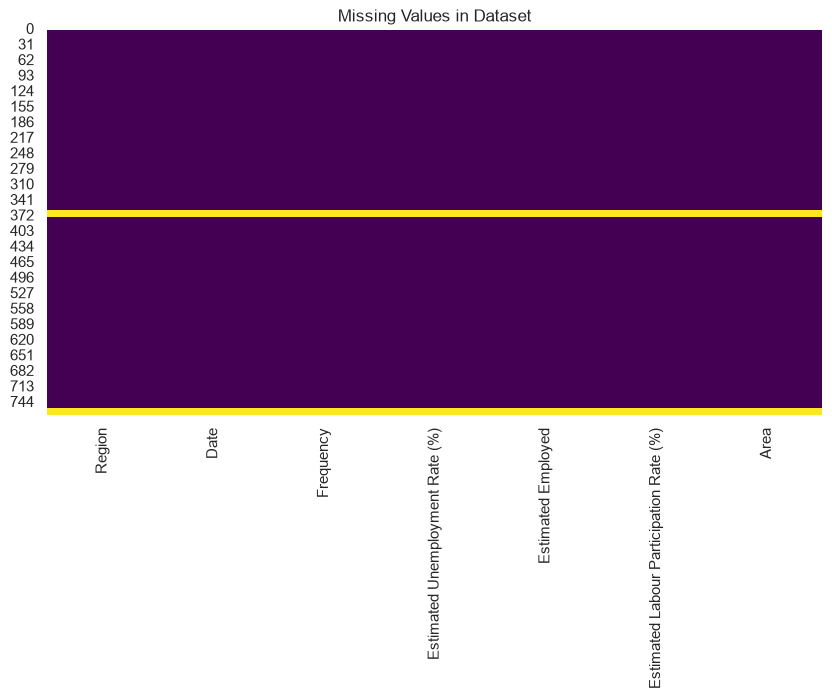

In [4]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Visualize Missing Values
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Values in Dataset")
plt.show()

### 5.Data Cleaning & Type Conversion

In [5]:
# Remove extra spaces from text columns
df["Region"] = df["Region"].astype("string").str.strip()
df["Area"] = df["Area"].astype("string").str.strip()

# Convert Date column into datetime
df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(), dayfirst=True, errors="coerce")

# Convert numerical columns
numeric_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove missing essential values
df.dropna(subset=["Region", "Date", "Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"], inplace=True)
df.reset_index(drop=True, inplace=True)
print("Data Cleaning Completed!")
display(df.head())
print("\nCleaned Dataset Shape:", df.shape)

Data Cleaning Completed!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural



Cleaned Dataset Shape: (740, 7)


### 6.Region-wise Analysis

In [6]:
region_avg = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False))
print("Region-wise Average Unemployment Rate:")
display(region_avg.to_frame("Average Unemployment Rate (%)"))

Region-wise Average Unemployment Rate:


,Average Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


### Region-wise Bar Chart

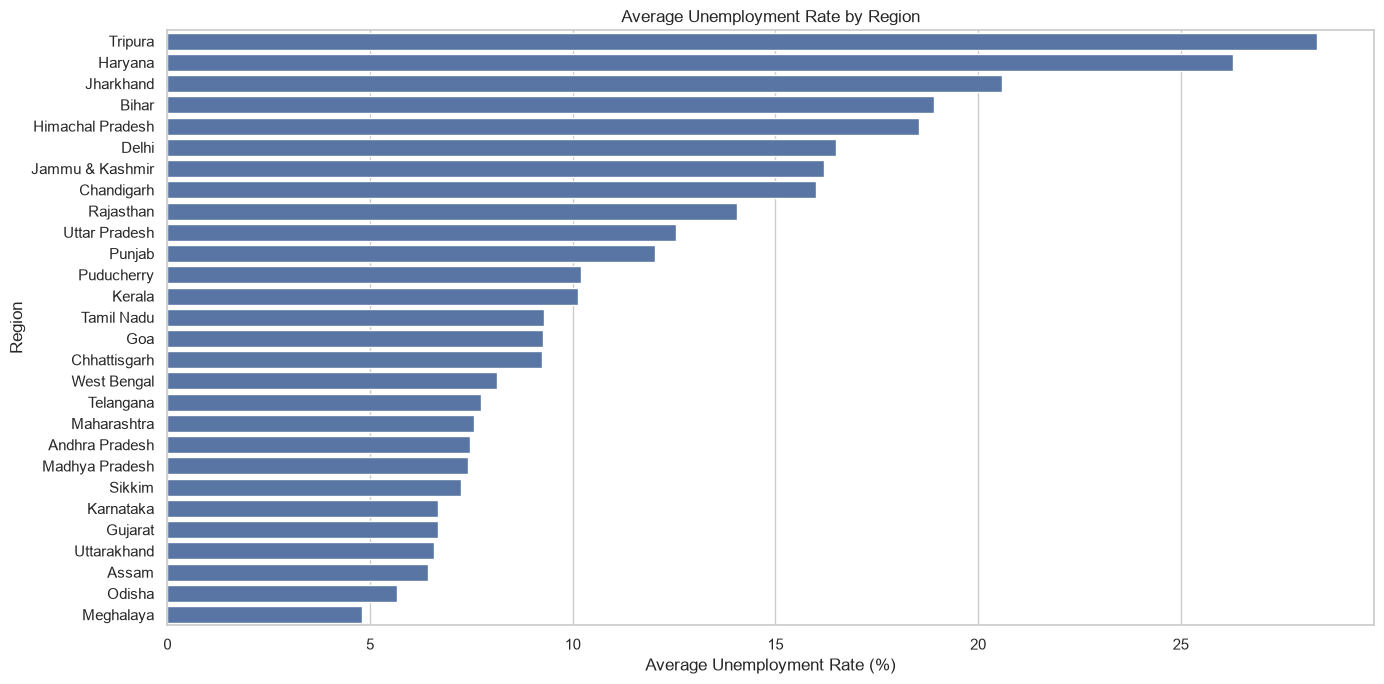

In [7]:
plt.figure(figsize=(14, 7))
sns.barplot(x=region_avg.values, y=region_avg.index)
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Written Observation (Markdown Cell)

### 7.Month-wise Trends

In [8]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)
monthly_trend = (df.groupby("Month")["Estimated Unemployment Rate (%)"].mean().reset_index())
display(monthly_trend.head())

,Month,Estimated Unemployment Rate (%)
0,2019-05,8.874259
1,2019-06,9.303333
2,2019-07,9.033889
3,2019-08,9.637925
4,2019-09,9.051731


### Monthly Time-Series Chart

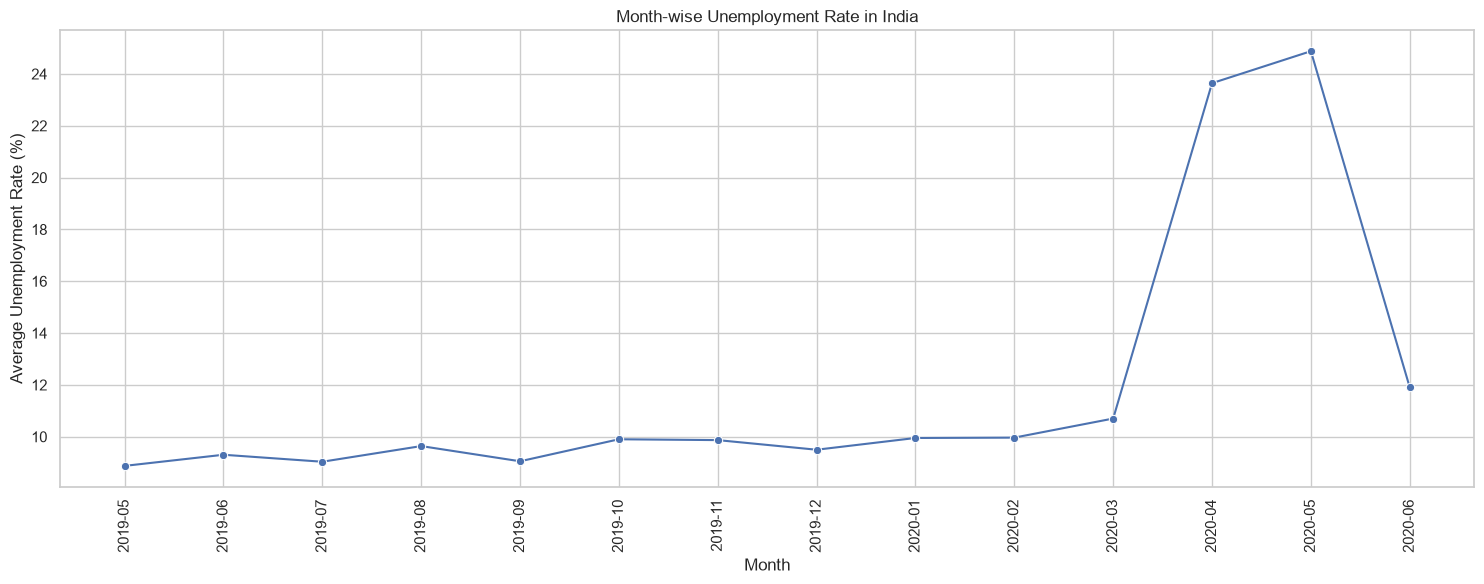

In [9]:
plt.figure(figsize=(15, 6))
sns.lineplot(data=monthly_trend, x="Month", y="Estimated Unemployment Rate (%)", marker="o")
plt.title("Month-wise Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Written Observation (Markdown Cell)

### 8.Three Major States Time-Series Chart

Available States:
<ArrowStringArray>
['Karnataka', 'Maharashtra', 'Uttar Pradesh']
Length: 3, dtype: string


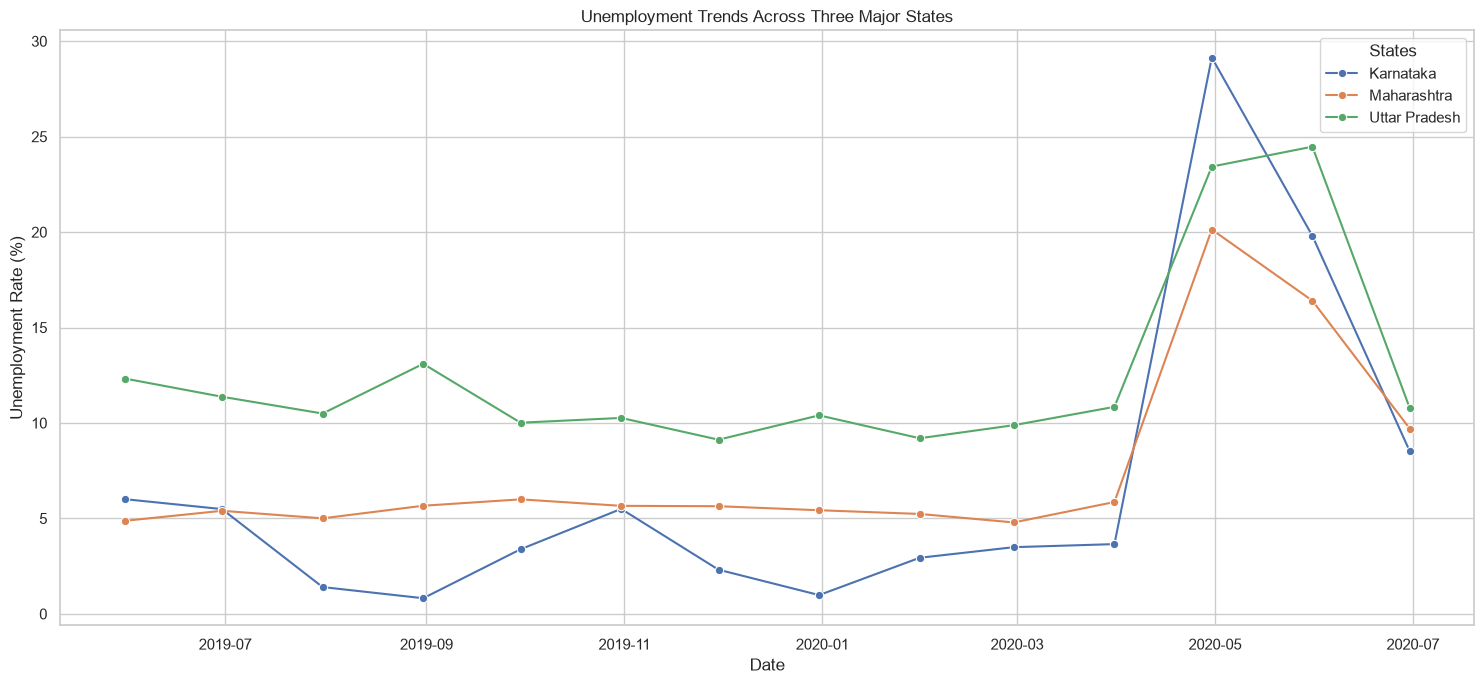

In [10]:
# Select three major states
states = ["Maharashtra", "Uttar Pradesh", "Karnataka"]
state_data = df[df["Region"].isin(states)].copy()

# Check available states
print("Available States:")
print(state_data["Region"].unique())

# Group by date and state
state_trend = (state_data.groupby(["Date", "Region"])["Estimated Unemployment Rate (%)"].mean().reset_index())

# Plot chart
plt.figure(figsize=(15, 7))
sns.lineplot(data=state_trend, x="Date", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")
plt.title("Unemployment Trends Across Three Major States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="States")
plt.tight_layout()
plt.show()

### Written Observation (Markdown Cell)

### 9.Top 10 States Bar Chart

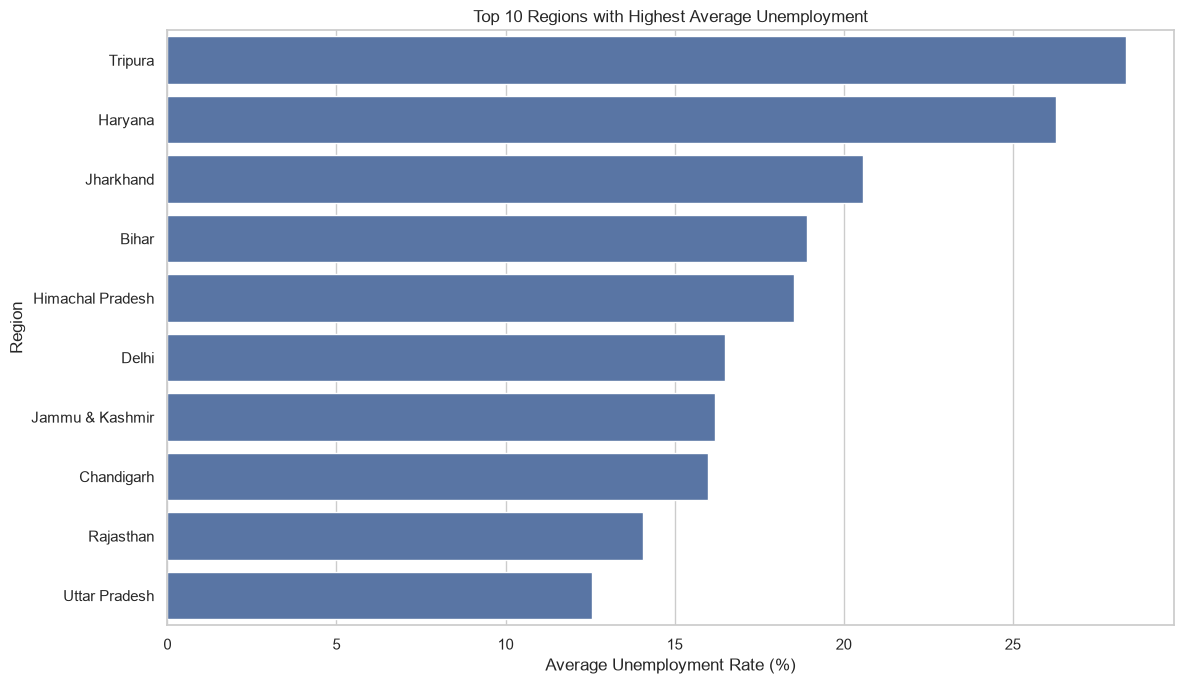

,Region,Estimated Unemployment Rate (%)
0,Tripura,28.350357
1,Haryana,26.283214
2,Jharkhand,20.585000
3,Bihar,18.918214
4,Himachal Pradesh,18.540357
5,Delhi,16.495357
6,Jammu & Kashmir,16.188571
7,Chandigarh,15.991667
8,Rajasthan,14.058214
9,Uttar Pradesh,12.551429


In [11]:
top_10 = region_avg.head(10).reset_index()
plt.figure(figsize=(12, 7))
sns.barplot(data=top_10, x="Estimated Unemployment Rate (%)", y="Region")
plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()
display(top_10)

### Written Observation (Markdown Cell)

### 10.Correlation Heatmap

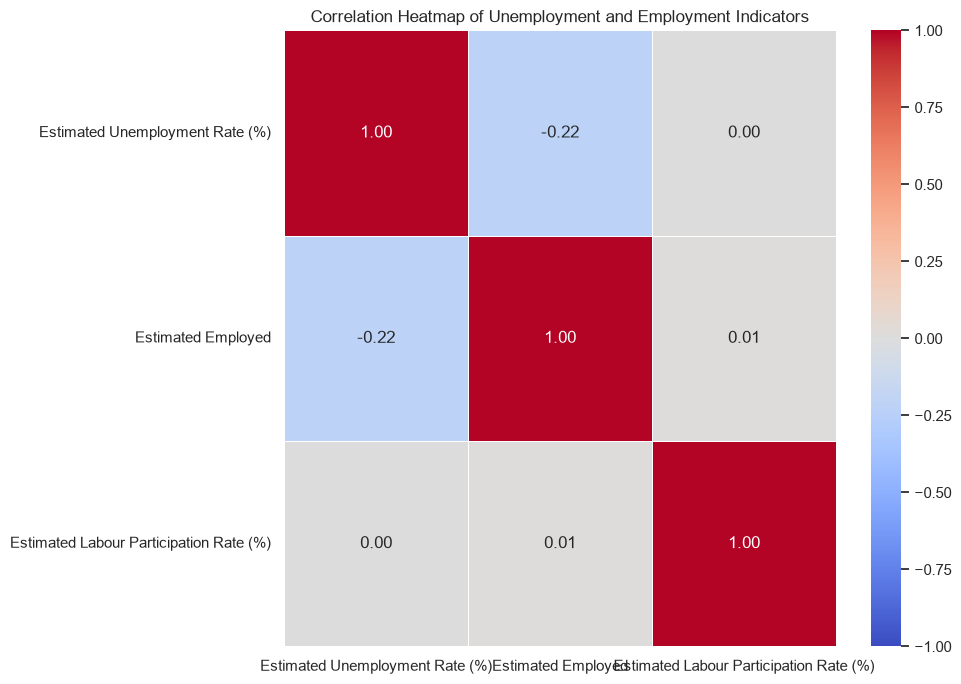

In [12]:
correlation_data = df[["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]]
correlation_matrix = correlation_data.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Unemployment and Employment Indicators")
plt.tight_layout()
plt.show()

### Written Observation (Markdown Cell)

### 11.Pre-COVID vs Post-COVID Analysis

In [13]:
# Define COVID period starting date
covid_date = pd.Timestamp("2020-03-01")

# Split dataset
pre_covid = df[df["Date"] < covid_date]
post_covid = df[df["Date"] >= covid_date]

# Calculate average unemployment rates
pre_covid_avg = (pre_covid["Estimated Unemployment Rate (%)"].mean())
post_covid_avg = (post_covid["Estimated Unemployment Rate (%)"].mean())
print("Pre-COVID Average Unemployment Rate:", round(pre_covid_avg, 2), "%")
print("Post-COVID Average Unemployment Rate:", round(post_covid_avg, 2), "%")
print("Difference:",
      round(post_covid_avg - pre_covid_avg, 2),
      "percentage points")

Pre-COVID Average Unemployment Rate: 9.51 %
Post-COVID Average Unemployment Rate: 17.77 %
Difference: 8.26 percentage points


### Pre-COVID vs Post-COVID Chart

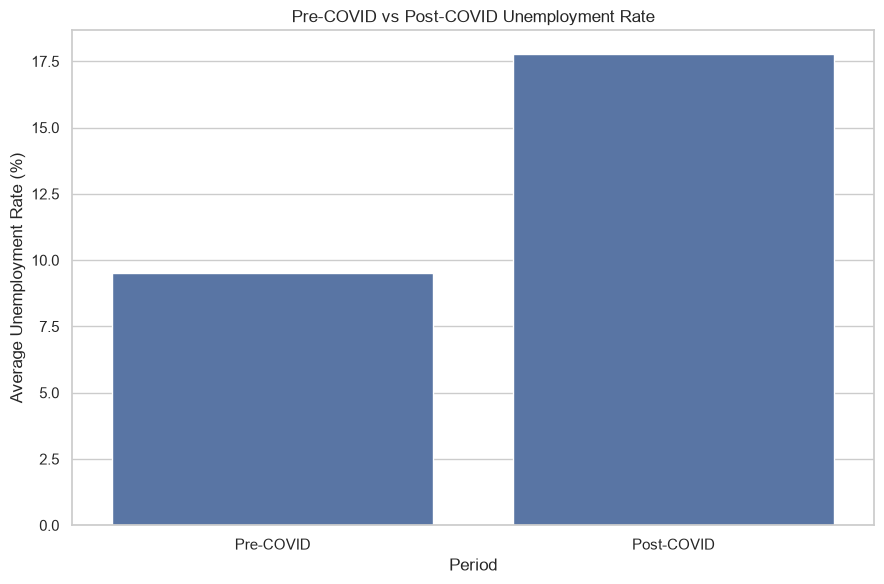

,Period,Average Unemployment Rate (%)
0,Pre-COVID,9.509534
1,Post-COVID,17.774363


In [14]:
covid_comparison = pd.DataFrame({"Period": ["Pre-COVID", "Post-COVID"], "Average Unemployment Rate (%)": [pre_covid_avg, post_covid_avg]})
plt.figure(figsize=(9, 6))
sns.barplot(data=covid_comparison, x="Period", y="Average Unemployment Rate (%)")
plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()
display(covid_comparison)

### Written Observation (Markdown Cell)

### 12.Written Observations – Final Summary

### 13. Final Findings & Cleaned Dataset Export

In [15]:
print("=" * 55)
print("       UNEMPLOYMENT ANALYSIS – FINAL FINDINGS")
print("=" * 55)

print("\nTotal Records Analyzed:", len(df))

print("\nDate Range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nHighest Unemployment Region:")
print(region_avg.idxmax(), "-", round(region_avg.max(), 2), "%")

print("\nLowest Unemployment Region:")
print(region_avg.idxmin(), "-", round(region_avg.min(), 2), "%")

print("\nPre-COVID Average:")
print(round(pre_covid_avg, 2), "%")

print("\nPost-COVID Average:")
print(round(post_covid_avg, 2), "%")

print("\nCOVID Period Difference:")
print(round(post_covid_avg - pre_covid_avg, 2), "percentage points")

print("\nAnalysis Completed Successfully!")

       UNEMPLOYMENT ANALYSIS – FINAL FINDINGS

Total Records Analyzed: 740

Date Range:
2019-05-31 00:00:00 to 2020-06-30 00:00:00

Highest Unemployment Region:
Tripura - 28.35 %

Lowest Unemployment Region:
Meghalaya - 4.8 %

Pre-COVID Average:
9.51 %

Post-COVID Average:
17.77 %

COVID Period Difference:
8.26 percentage points

Analysis Completed Successfully!


### Export Cleaned Dataset

In [16]:
df.to_csv("cleaned_unemployment_data.csv", index=False)
print("Cleaned Dataset Exported Successfully!")

Cleaned Dataset Exported Successfully!
